# xT (Expected Threat) con socceraction: Mundial 2022

Entreno un modelo de xT con los 64 partidos del Mundial 2022 y lo uso para valorar a los jugadores de **Países Bajos 2-2 Argentina** (cuartos de final).

**Datos:** [StatsBomb Open Data](https://github.com/statsbomb/open-data), vía `socceraction`.
**Formato:** SPADL, acciones con punto de inicio y fin.
**Filtro:** `period_id <= 4`, sin la tanda de penaltis.

## 1. Carga de datos
`StatsBombLoader` lee los datos abiertos. Aquí el identificador de partido se llama `game_id`.

In [1]:
import warnings
import pandas as pd
from socceraction.data.statsbomb import StatsBombLoader
import socceraction.spadl as spadl

warnings.filterwarnings("ignore")

SBL = StatsBombLoader(getter="remote", creds={"user": None, "passwd": None})
games = SBL.games(43, 106)
print(len(games))
games[["game_id", "game_date", "home_team_id", "away_team_id", "competition_stage"]].head()

64


,game_id,game_date,home_team_id,away_team_id,competition_stage
0,3857276,2022-12-01 15:00:00,1833,788,Group Stage
1,3857271,2022-11-21 13:00:00,768,797,Group Stage
2,3857296,2022-12-01 15:00:00,785,782,Group Stage
3,3857274,2022-11-25 16:00:00,941,3565,Group Stage
4,3857255,2022-12-01 19:00:00,778,772,Group Stage


## 2. De eventos a acciones (SPADL)
Convierto los eventos de un partido al formato SPADL. Pasan de 4708 eventos a 2739 acciones, y un pase y su recepción quedan en una sola acción con inicio y fin.

In [2]:
partido = games[games["game_id"] == 3869321].iloc[0]

events = SBL.events(partido.game_id)
actions = spadl.statsbomb.convert_to_actions(events, partido.home_team_id)
actions = spadl.add_names(actions)

print(events.shape, "->", actions.shape)
actions[["period_id", "time_seconds", "team_id", "player_id",
         "start_x", "start_y", "end_x", "end_y",
         "type_name", "result_name"]].head(6)

(4708, 26) -> (2739, 17)


,period_id,time_seconds,team_id,player_id,start_x,start_y,end_x,end_y,type_name,result_name
0,1,0.335,941,2988.0,52.45625,34.0425,31.71875,38.3775,pass,success
1,1,2.047,941,3306.0,31.71875,38.3775,32.24375,37.6975,dribble,success
2,1,3.509,941,3306.0,32.24375,37.6975,68.55625,2.7625,pass,success
3,1,6.629,941,8125.0,68.55625,2.7625,70.48125,12.1125,pass,fail
4,1,9.346,941,6994.0,70.13125,11.4325,70.13125,11.4325,foul,fail
5,1,29.166,779,38718.0,69.60625,11.6875,78.18125,38.5475,freekick_short,success


## 3. Entrenar el modelo de xT
Convierto los 64 partidos y giro el campo (`play_left_to_right`) para que todos los equipos ataquen hacia la derecha. Excluyo la tanda de penaltis.

In [3]:
all_actions = []
for g in games.itertuples():
    ev = SBL.events(g.game_id)
    a = spadl.statsbomb.convert_to_actions(ev, g.home_team_id)
    a = spadl.add_names(a)
    a = spadl.play_left_to_right(a, g.home_team_id)
    a["game_id"] = g.game_id
    all_actions.append(a)

all_actions = pd.concat(all_actions, ignore_index=True)
all_actions = all_actions[all_actions["period_id"] <= 4]
print(all_actions.shape)

(138905, 17)


El modelo divide el campo en una cuadrícula de 16 por 12 zonas y aprende cuánto peligro tiene cada una.

In [4]:
import socceraction.xthreat as xthreat

xt_model = xthreat.ExpectedThreat(l=16, w=12)
xt_model.fit(all_actions)
print(xt_model.xT.shape)

# iterations:  50
(12, 16)


## 4. Valorar el Países Bajos-Argentina
Cada pase o conducción vale lo que sube el peligro entre su zona de inicio y su zona de fin. Me quedo solo con pases y conducciones.

In [5]:
partido_actions = all_actions[all_actions["game_id"] == 3869321].copy()
partido_actions["xt"] = xt_model.rate(partido_actions, use_interpolation=False)

mov = partido_actions[partido_actions["type_name"].isin(["pass", "dribble"])]
print(len(mov), round(mov["xt"].sum(), 2))

2287 1.53


### Ranking de jugadores por xT acumulado
Suma del xT de todos sus pases y conducciones en el partido (incluye prórroga).

In [6]:
jugadores = SBL.players(3869321).drop_duplicates("player_id").set_index("player_id")
nombres = {941: "Países Bajos", 779: "Argentina"}

ranking = (
    mov.groupby(["player_id", "team_id"])["xt"].sum()
    .sort_values(ascending=False)
    .head(8)
    .reset_index()
)
ranking["jugador"] = ranking["player_id"].map(jugadores["player_name"])
ranking["equipo"] = ranking["team_id"].map(nombres)
ranking[["jugador", "equipo", "xt"]].round(2)

,jugador,equipo,xt
0,Lionel Andrés Messi Cuccittini,Argentina,0.21
1,Virgil van Dijk,Países Bajos,0.16
2,Nahuel Molina Lucero,Argentina,0.15
3,Cody Mathès Gakpo,Países Bajos,0.14
4,Jurriën David Norman Timber,Países Bajos,0.13
5,Andries Noppert,Países Bajos,0.11
6,Marcos Javier Acuña,Argentina,0.11
7,Frenkie de Jong,Países Bajos,0.08


### Acciones de mayor xT de Noppert

In [7]:
mov[mov["player_id"] == jugadores[jugadores["player_name"].str.contains("Noppert")].index[0]][["time_seconds", "start_x", "end_x", "type_name", "xt"]].sort_values("xt", ascending=False).head(5)


,time_seconds,start_x,end_x,type_name,xt
53454,2947.256,9.93125,66.36875,pass,0.011700
53219,1738.282,17.71875,88.68125,pass,0.011687
53821,725.434,2.58125,53.33125,pass,0.008065
53900,92.820,5.38125,55.60625,pass,0.007261
53827,739.648,10.80625,54.46875,pass,0.006975


### Acciones de Noppert y cuántas suman xT

In [8]:
noppert = mov[mov["player_id"] == jugadores[jugadores["player_name"].str.contains("Noppert")].index[0]]
print(len(noppert), int((noppert["xt"] > 0).sum()))

77 46


## 5. Mapa de xT del campo
Cuanto más rojo, más peligro tiene tener el balón en esa zona. El equipo ataca hacia la derecha.

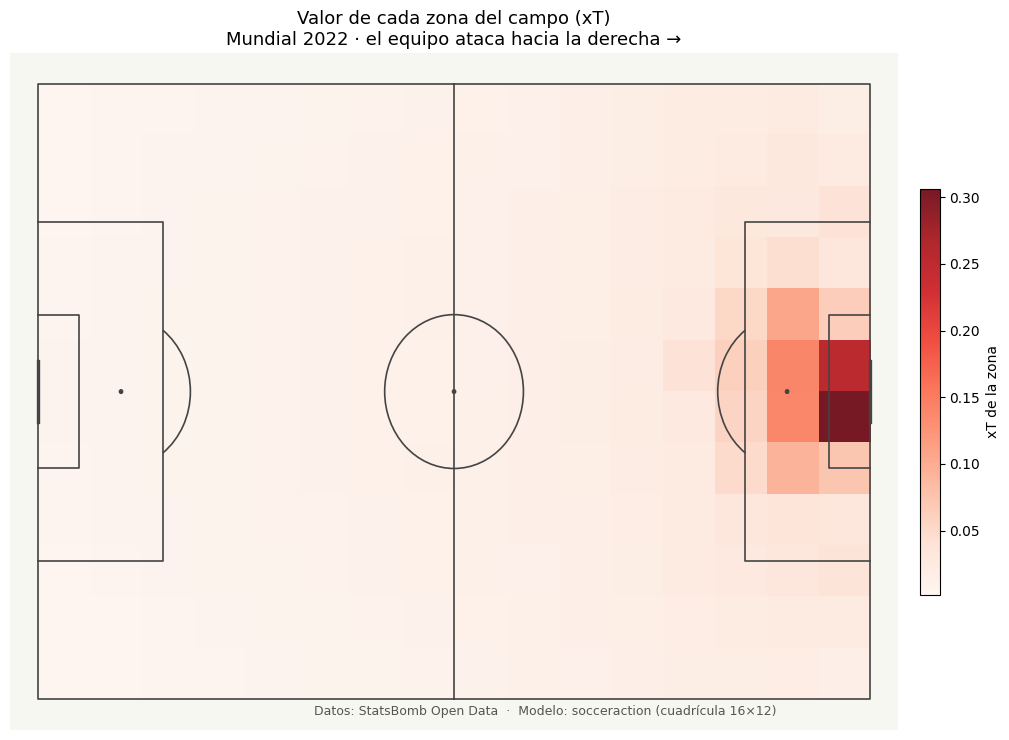

In [9]:
import matplotlib.pyplot as plt
from mplsoccer import Pitch

from pathlib import Path
Path("images").mkdir(exist_ok=True)

pitch = Pitch(pitch_type="statsbomb", pitch_color="#f7f7f2", line_color="#444444", linewidth=1.2)
fig, ax = pitch.draw(figsize=(11, 7.5))
im = ax.imshow(xt_model.xT, extent=(0, 120, 80, 0), cmap="Reds", aspect="auto", alpha=0.9)
cbar = fig.colorbar(im, ax=ax, shrink=0.6, pad=0.02)
cbar.set_label("xT de la zona")
ax.set_title("Valor de cada zona del campo (xT)\nMundial 2022 · el equipo ataca hacia la derecha →", fontsize=13)
fig.text(0.5, 0.04, "Datos: StatsBomb Open Data  ·  Modelo: socceraction (cuadrícula 16×12)",
         ha="center", fontsize=9, color="#555555")
fig.savefig("images/mapa_xt.png", dpi=150, bbox_inches="tight")
plt.show()

### xT por 90 minutos
Normalizo el xT por los minutos jugados (`minutes_played`), para corregir el efecto de la prórroga y de los jugadores que salieron antes. Excluyo a quien jugó menos de 45 minutos, porque con tan pocos minutos el dato es poco fiable.

In [10]:
minutos = jugadores["minutes_played"]

r = mov.groupby(["player_id", "team_id"])["xt"].sum().reset_index()
r["jugador"] = r["player_id"].map(jugadores["player_name"])
r["equipo"] = r["team_id"].map(nombres)
r["minutos"] = r["player_id"].map(minutos)
r["xt_90"] = r["xt"] / r["minutos"] * 90

r[r["minutos"] >= 45].sort_values("xt_90", ascending=False).head(8)[
    ["jugador", "equipo", "minutos", "xt", "xt_90"]].round(2)

,jugador,equipo,minutos,xt,xt_90
6,Lionel Andrés Messi Cuccittini,Argentina,139,0.21,0.14
21,Marcos Javier Acuña,Argentina,83,0.11,0.11
30,Nahuel Molina Lucero,Argentina,123,0.15,0.11
5,Virgil van Dijk,Países Bajos,139,0.16,0.10
20,Leandro Daniel Paredes,Argentina,68,0.07,0.10
24,Cody Mathès Gakpo,Países Bajos,130,0.14,0.10
26,Jurriën David Norman Timber,Países Bajos,139,0.13,0.08
23,Cristian Gabriel Romero,Argentina,83,0.07,0.08


### Las 10 acciones de mayor xT de cada equipo
Cada flecha es un pase o conducción: empieza donde se originó y acaba donde terminó. Se muestran las 10 de mayor xT de cada equipo, y ambos atacan hacia la derecha.

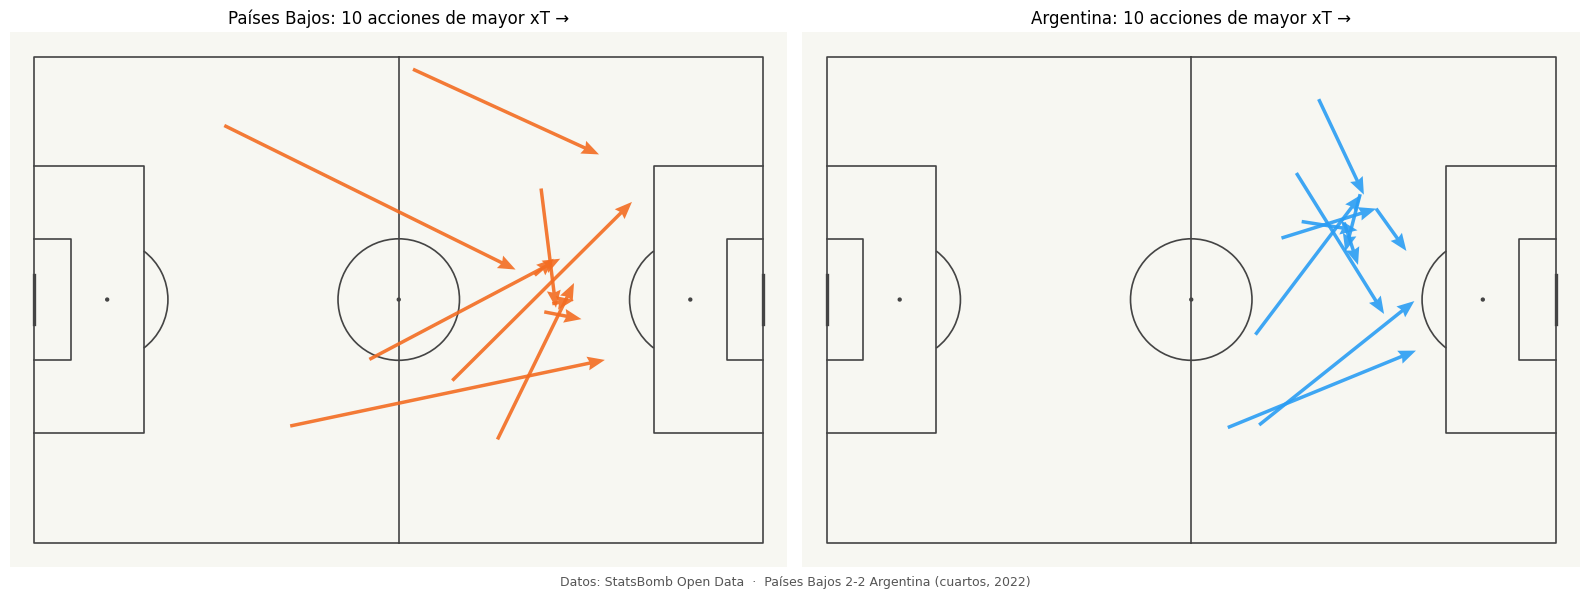

In [11]:
colores = {941: "#f36c21", 779: "#2a9df4"}

pitch = Pitch(pitch_type="statsbomb", pitch_color="#f7f7f2", line_color="#444444", linewidth=1.2)
fig, axs = pitch.draw(nrows=1, ncols=2, figsize=(16, 6))
for ax, tid in zip(axs, [941, 779]):
    top = mov[mov["team_id"] == tid].sort_values("xt", ascending=False).head(10)
    pitch.arrows(top["start_x"], top["start_y"], top["end_x"], top["end_y"],
                 ax=ax, color=colores[tid], width=2.5, headwidth=4, alpha=0.9)
    ax.set_title(f"{nombres[tid]}: 10 acciones de mayor xT →", fontsize=12)
fig.text(0.5, 0.02, "Datos: StatsBomb Open Data  ·  Países Bajos 2-2 Argentina (cuartos, 2022)",
         ha="center", fontsize=9, color="#555555")
fig.savefig("images/acciones_xt.png", dpi=130, bbox_inches="tight")
plt.show()

### xT total por equipo
Suma del xT de todos los pases y conducciones de cada equipo. `941` es Países Bajos y `779` es Argentina.

In [12]:
mov.groupby("team_id")["xt"].sum().round(2)

team_id
779    0.86
941    0.67
Name: xt, dtype: float64

### Gráfico: xT por 90 minutos
Los 8 jugadores con más xT por 90 minutos (mínimo 45 minutos jugados). El color indica el equipo.

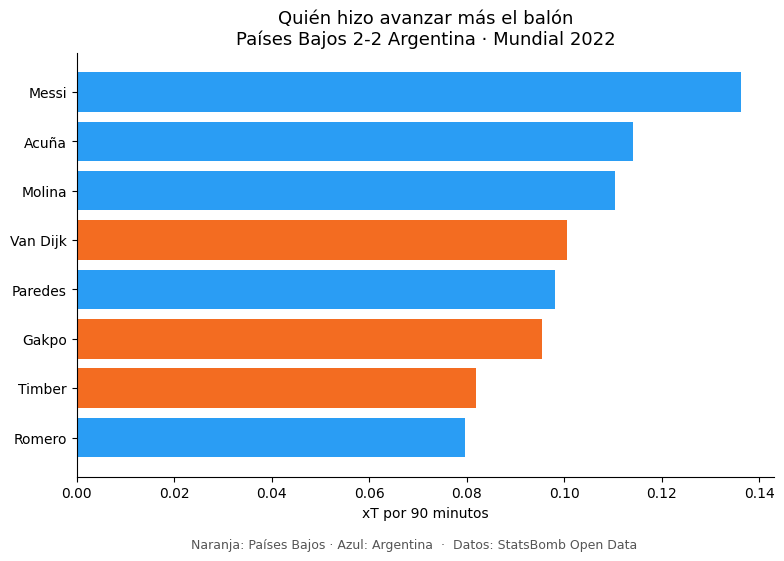

In [13]:
cortos = {"Lionel Andrés Messi Cuccittini": "Messi", "Marcos Javier Acuña": "Acuña",
          "Nahuel Molina Lucero": "Molina", "Virgil van Dijk": "Van Dijk",
          "Leandro Daniel Paredes": "Paredes", "Cody Mathès Gakpo": "Gakpo",
          "Jurriën David Norman Timber": "Timber", "Cristian Gabriel Romero": "Romero"}

top = r[r["minutos"] >= 45].sort_values("xt_90", ascending=False).head(8).sort_values("xt_90")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["jugador"].map(cortos).fillna(top["jugador"]), top["xt_90"],
        color=top["team_id"].map(colores))
ax.set_xlabel("xT por 90 minutos")
ax.set_title("Quién hizo avanzar más el balón\nPaíses Bajos 2-2 Argentina · Mundial 2022", fontsize=13)
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Naranja: Países Bajos · Azul: Argentina  ·  Datos: StatsBomb Open Data",
         ha="center", fontsize=9, color="#555555")
fig.savefig("images/xt_por_90.png", dpi=150, bbox_inches="tight")
plt.show()

### Ranking solo con pases

In [14]:
sp = mov[mov["type_name"] == "pass"].groupby("player_id")["xt"].sum().sort_values(ascending=False).head(5).reset_index()
sp["jugador"] = sp["player_id"].map(jugadores["player_name"])
sp[["jugador", "xt"]].round(2)

,jugador,xt
0,Virgil van Dijk,0.14
1,Cody Mathès Gakpo,0.12
2,Lionel Andrés Messi Cuccittini,0.12
3,Andries Noppert,0.11
4,Jurriën David Norman Timber,0.10


### xT acumulado a lo largo del partido
Cada línea suma el xT de los pases y conducciones de un equipo a medida que avanza el partido. Las líneas punteadas son los goles y las grises marcan el descanso y la prórroga.

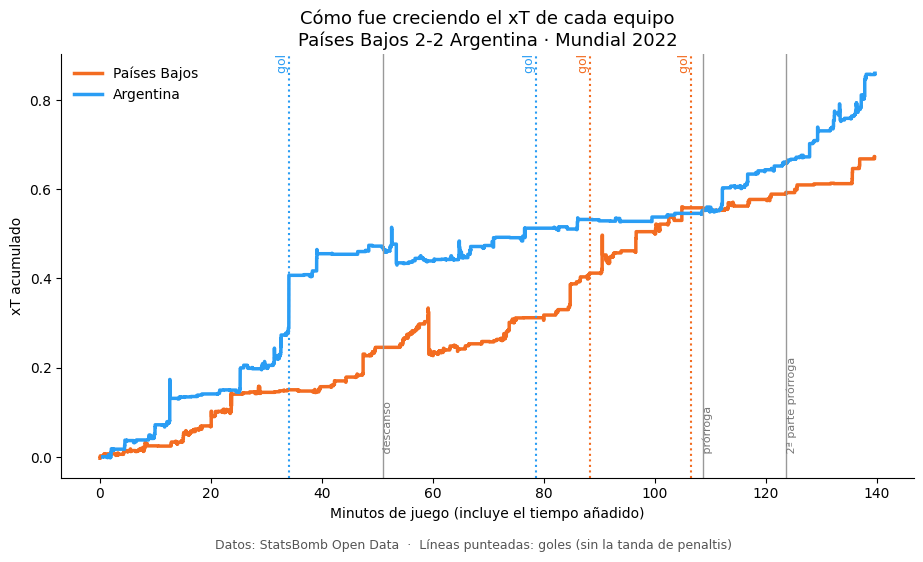

In [15]:
duracion = partido_actions.groupby("period_id")["time_seconds"].max()
inicio = duracion.cumsum().shift(fill_value=0)

mov_t = mov.copy()
mov_t["minuto"] = (mov_t["time_seconds"] + mov_t["period_id"].map(inicio)) / 60

goles = partido_actions[partido_actions["type_name"].isin(["shot", "shot_penalty", "shot_freekick"])
                        & (partido_actions["result_name"] == "success")].copy()
goles["minuto"] = (goles["time_seconds"] + goles["period_id"].map(inicio)) / 60

fig, ax = plt.subplots(figsize=(11, 5.5))
for tid in [941, 779]:
    m = mov_t[mov_t["team_id"] == tid].sort_values("minuto")
    ax.step(m["minuto"], m["xt"].fillna(0).cumsum(), where="post", color=colores[tid], lw=2.5, label=nombres[tid])

for tid, minuto in zip(goles["team_id"], goles["minuto"]):
    ax.axvline(minuto, color=colores[tid], ls=":", lw=1.5)
    ax.text(minuto, ax.get_ylim()[1], " gol", rotation=90, va="top", ha="right", fontsize=9, color=colores[tid])

for p_id, texto in [(2, "descanso"), (3, "prórroga"), (4, "2ª parte prórroga")]:
    ax.axvline(inicio[p_id] / 60, color="#999999", lw=1)
    ax.text(inicio[p_id] / 60, 0, f" {texto}", rotation=90, va="bottom", ha="left", fontsize=8, color="#777777")

ax.set_xlabel("Minutos de juego (incluye el tiempo añadido)")
ax.set_ylabel("xT acumulado")
ax.set_title("Cómo fue creciendo el xT de cada equipo\nPaíses Bajos 2-2 Argentina · Mundial 2022", fontsize=13)
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.5, -0.02, "Datos: StatsBomb Open Data  ·  Líneas punteadas: goles (sin la tanda de penaltis)",
         ha="center", fontsize=9, color="#555555")
fig.savefig("images/xt_tiempo.png", dpi=150, bbox_inches="tight")
plt.show()

### Las 3 acciones con peor xT (la caída del minuto 59)

In [16]:
mov.sort_values("xt").head(3)[["period_id", "time_seconds", "team_id", "start_x", "end_x", "type_name", "xt"]]

,period_id,time_seconds,team_id,start_x,end_x,type_name,xt
52795,2,494.435,941,97.51875,62.51875,dribble,-0.093937
53348,2,2372.579,941,97.69375,91.48125,pass,-0.044288
52609,2,143.487,779,100.66875,89.73125,pass,-0.043247


## Conclusiones

- **Qué mide el xT:** cuánto avanza el balón hacia zonas de peligro con cada pase o conducción. No mide cuántas ocasiones se crean ni lo difícil que es cada pase.
- **Países Bajos-Argentina:** Messi lidera el ranking con 0,21 de xT y sigue primero al normalizar por 90 minutos (0,14). Argentina suma 0,86 en total frente a los 0,67 de Países Bajos, así que movió el balón con algo más de peligro en un partido que acabó 2-2. Si solo se cuentan pases, Van Dijk pasa a liderar (0,14) y Messi baja al tercer puesto (0,12).
- **Cómo evolucionó el partido:** Argentina acumula más xT durante casi todo el partido, con un salto importante justo antes de su primer gol. Países Bajos recorta en la segunda parte, cuando iba perdiendo, y casi la alcanza al final del tiempo reglamentario. En la prórroga Argentina vuelve a distanciarse. La línea baja en algunos momentos porque los pases y conducciones que alejan el balón del área tienen xT negativo.
- **Estilo de cada equipo:** entre las 10 acciones de mayor xT, las de Países Bajos son de media más largas y arrancan más atrás, mientras que las de Argentina son más cortas y empiezan más cerca del área rival.
- **Caso Noppert:** el portero de Países Bajos acumula 0,11 de xT (sexto del ranking). Viene de sumar 77 acciones, de las cuales 46 son positivas. Sus cinco acciones más valiosas son pases largos desde su área y valen entre 0,007 y 0,012 cada una, así que el valor sale de acumular muchos avances pequeños, no de crear ocasiones. Al normalizar por 90 minutos ya no aparece entre los 8 primeros, así que parte de su xT se explica por los minutos jugados.
- **El mapa:** el peligro se concentra dentro del área rival, y el centro del campo y las bandas valen poco por sí solos. Eso explica que el xT premie los pases que acercan el balón al área.
- **Limitaciones:** el xT premia el avance y no la dificultad del pase. Las conducciones no vienen de los datos, sino que las infiere socceraction entre acciones consecutivas, y a veces unen cosas que no son una conducción real: la mayor caída del gráfico (minuto 59, −0,09) es una "conducción" de 35 metros entre un pase fallado y un saque de banda. Además pesan mucho: si solo se cuentan pases, cambia el orden del ranking. Con un solo partido valorado no se puede generalizar, y la cuadrícula, entrenada con 64 partidos, también tiene algo de ruido.